# MAttr reproduction on standardized MIB IOI

This interface launches the **official** node-level MAttr recipe in the isolated Ubuntu environment, then reads saved artifacts. It does not import the Windows Sketch-ACDC model environment into training. Previous experiments and reports remain unchanged.

Inspected MAttr commit: `af82b2eef145dd3e66c793a413352d6931a152d7`; its required MIB fork is pinned to `582fdbc`, with EAP-IG submodule `3fb341e`. The README's Python 3.12/default `lm` dependency group is separate from the older project's stack. See `scripts/mattr/setup_wsl.sh` for the inspected installation and official tests.

Source: [official repository](https://github.com/aryamanarora/matryoshka-attribution). Measurements below appear only after execution.

In [1]:
from pathlib import Path
import json, os, subprocess, sys
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next((p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents] if (p/'scripts/mattr').is_dir()),None)
assert ROOT is not None, 'Open this notebook from inside the project checkout.'
# Set to an existing campaign to resume; each job has its own completion marker.
campaigns=sorted(p for p in (ROOT/'results/mattr_reproduction').glob('*') if p.is_dir()) if (ROOT/'results/mattr_reproduction').exists() else []
RESULTS=Path('H:\\GenAI Research\\sketch_prune\\results\\mattr_reproduction\\20261015T223201Z')
SEEDS=[42,43,44]
DISCOVERY_SIZES=[16,32,64,128]
VALIDATION_N=128
STEPS=500
RUN_TESTS=False
RUN_SMOKE=False
RUN_REFERENCE=False
RUN_SCALING=False
RUN_BASELINES=False
RUN_CHECKPOINT_EVALUATIONS=False
RUN_PUBLIC_CONFIRMATION=False
RUN_INTERACTIONS=False  # exploratory; not part of the reference reproduction
print('Results:',RESULTS)
print('Fixed seeds:',SEEDS,'discovery pools:',DISCOVERY_SIZES,'validation:',VALIDATION_N)
assert SEEDS==[42,43,44] and DISCOVERY_SIZES==[16,32,64,128] and VALIDATION_N==128 and STEPS==500, 'These constants describe the fixed protocol; use a new script configuration/output directory to change it.'
def linux_path(path):
    path=Path(path).resolve()
    return '/mnt/'+path.drive[0].lower()+path.as_posix()[2:] if os.name=='nt' else str(path)
def run_stage(stage):
    script=ROOT/'scripts/mattr/campaign_wsl.sh'
    argv=['bash',linux_path(script),'--out',linux_path(RESULTS),'--stage',stage]
    if os.name=='nt': argv=['wsl','-d','Ubuntu','--']+argv
    print('Running:',argv)
    subprocess.run(argv,check=True,cwd=ROOT)

Results: H:\GenAI Research\sketch_prune\results\mattr_reproduction\20261015T223201Z
Fixed seeds: [42, 43, 44] discovery pools: [16, 32, 64, 128] validation: 128


## Gates and reference

The campaign first requires the official unit tests, wrapper/resume tests, and a short real GPT-2 training/evaluation smoke. The reference keeps Adam lr 0.05, 500 steps, soft sigmoid top-k, uniform sparsity, iso/denoising, and the learned input node. The uncapped reference follows the documented full-data command. Comparisons subsequently use one fixed 128-prompt validation cohort; the reference ranking is also evaluated on that cohort so unlike cohorts are not mixed.

Training samples with replacement. Configured unique pool size, actually sampled unique prompts, and total presentations are separate fields. Safe resumption restores official Adam state, scores, and Python/Torch RNGs; source/configuration identities must match.

In [2]:
if RUN_TESTS: run_stage('tests')
if RUN_SMOKE: run_stage('smoke')
if RUN_REFERENCE: run_stage('reference')
if RUN_SCALING: run_stage('scaling')
if RUN_BASELINES: run_stage('baselines')
if RUN_CHECKPOINT_EVALUATIONS: run_stage('checkpoints')
if RUN_PUBLIC_CONFIRMATION: run_stage('confirmation')
if RUN_INTERACTIONS:
    raise NotImplementedError('Exploratory interactions remain gated until the main reproduction is reviewed.')
if any([RUN_SMOKE,RUN_REFERENCE,RUN_SCALING,RUN_BASELINES,RUN_CHECKPOINT_EVALUATIONS,RUN_PUBLIC_CONFIRMATION]):
    run_stage('report')


## Circuit quality and compute

All compared methods use the official MIB node evaluator, signed ranking (`absolute=False`), counterfactual patching, and its ten retained-fraction points. `area_under` is the linear-fraction AUC of normalized **logit difference** (CPR); `area_from_1` integrates absolute deviation from one (CMD label in the official CLI); `acc_auc` separately integrates positive-logit-difference accuracy over log sparsity. Weighted edge count is not retained-node count. These are local public-split measurements, not a private leaderboard score.

Equal eligible discovery data is **not** equal compute. Attribution construction and evaluation are timed separately, including forwards, backwards, optimization, preparation, CPU memory, and synchronized CUDA timing. EAP/EAP-IG attribution uses batch size 1 so the official mean-loss accumulation weights examples uniformly; all methods retain evaluation batch size 20.

In [3]:
tables={}
views={
    'training_results':['kind','discovery_pool','seed','sampled_unique','presentations','cpr_auc','cmd_auc','accuracy_auc','construction_wall_seconds','validation_wall_seconds'],
    'dataset_scaling':['method','discovery_pool','runs','validation_cpr_mean','validation_cpr_std','cmd_mean','accuracy_auc_mean','construction_seconds_mean','gap_mean'],
    'mattr_vs_eap':['method','discovery_pool','seed','cpr_auc','cmd_auc','accuracy_auc','input_node_rank','construction_wall_seconds'],
    'quality_vs_compute':['method','discovery_pool','seed','cpr_auc','accuracy_auc','matched_protocol_wall_seconds','attribution_forward_batches','attribution_backward_calls'],
    'checkpoint_quality':['discovery_pool','seed','step','train_cpr_auc','validation_cpr_auc','train_validation_gap','training_seconds_to_checkpoint'],
    'public_test_confirmation':['method','discovery_pool','seed','test_examples','cpr_auc','cmd_auc','accuracy_auc','process_wall_seconds']}
for name in ['training_results','dataset_scaling','mattr_vs_eap','quality_vs_compute','checkpoint_quality','stage_summary','training_curves','public_test_confirmation']:
    path=RESULTS/(name+'.csv')
    if path.exists():
        tables[name]=pd.read_csv(path)
        print('\n'+name+': '+str(len(tables[name]))+' rows; full table: '+str(path))
        columns=[c for c in views.get(name,tables[name].columns) if c in tables[name].columns]
        display(tables[name][columns].head(24) if name=='training_curves' else tables[name][columns])
    else: print(name+': not measured yet')



training_results: 13 rows; full table: H:\GenAI Research\sketch_prune\results\mattr_reproduction\20261015T223201Z\training_results.csv


,kind,discovery_pool,seed,sampled_unique,presentations,cpr_auc,cmd_auc,accuracy_auc,construction_wall_seconds,validation_wall_seconds
0,reference,10000,42,489,500,1.832010,0.973058,0.410602,74.194859,2021.453950
1,scaling,128,42,128,500,1.857128,0.997698,0.417206,54.649610,27.280996
2,scaling,128,43,125,500,1.849319,0.998319,0.414476,53.190851,27.511914
3,scaling,128,44,126,500,1.852486,0.993056,0.410151,55.126093,27.771241
4,scaling,16,42,16,500,1.810266,0.950836,0.414854,49.008815,25.660714
5,scaling,16,43,16,500,1.841976,0.982546,0.417206,50.620684,32.232554
6,scaling,16,44,16,500,1.866762,1.003702,0.419937,53.777089,25.705499
7,scaling,32,42,32,500,1.848417,0.997247,0.412124,51.114999,26.653612
8,scaling,32,43,32,500,1.829456,0.988529,0.409367,50.715283,27.545110
9,scaling,32,44,32,500,1.844933,0.993933,0.414476,54.948165,29.852030



dataset_scaling: 12 rows; full table: H:\GenAI Research\sketch_prune\results\mattr_reproduction\20261015T223201Z\dataset_scaling.csv


,method,discovery_pool,runs,validation_cpr_mean,validation_cpr_std,cmd_mean,accuracy_auc_mean,construction_seconds_mean,gap_mean
0,EAP,16,3,0.250000,1.715034e-08,0.749000,0.101723,23.301799,2.373860e-08
1,EAP,32,3,0.250000,1.251739e-08,0.749000,0.101723,26.112140,-7.381985e-08
2,EAP,64,3,0.250000,2.634180e-08,0.749000,0.101723,31.069902,2.867175e-08
3,EAP,128,3,0.250000,4.916860e-08,0.749000,0.101723,46.355426,-3.065074e-08
4,EAP-IG,16,3,1.595197,3.477868e-02,0.787954,0.386287,27.730157,8.193071e-03
5,EAP-IG,32,3,1.594060,3.905555e-02,0.782914,0.391033,40.911760,8.152148e-02
6,EAP-IG,64,3,1.587601,1.471395e-02,0.775041,0.392643,60.111832,6.247192e-02
7,EAP-IG,128,3,1.580377,3.849800e-03,0.773055,0.388378,109.992844,5.477142e-02
8,MAttr,16,3,1.839668,2.831891e-02,0.979028,0.417332,51.135529,8.043974e-02
9,MAttr,32,3,1.840935,1.009271e-02,0.993236,0.411989,52.259483,1.344731e-01



mattr_vs_eap: 36 rows; full table: H:\GenAI Research\sketch_prune\results\mattr_reproduction\20261015T223201Z\mattr_vs_eap.csv


,method,discovery_pool,seed,cpr_auc,cmd_auc,accuracy_auc,input_node_rank,construction_wall_seconds
0,MAttr,128,42,1.857128,0.997698,0.417206,6,54.649610
1,MAttr,128,43,1.849319,0.998319,0.414476,8,53.190851
2,MAttr,128,44,1.852486,0.993056,0.410151,7,55.126093
3,MAttr,16,42,1.810266,0.950836,0.414854,7,49.008815
4,MAttr,16,43,1.841976,0.982546,0.417206,6,50.620684
5,MAttr,16,44,1.866762,1.003702,0.419937,5,53.777089
6,MAttr,32,42,1.848417,0.997247,0.412124,7,51.114999
7,MAttr,32,43,1.829456,0.988529,0.409367,7,50.715283
8,MAttr,32,44,1.844933,0.993933,0.414476,8,54.948165
9,MAttr,64,42,1.842532,0.983102,0.417206,6,53.770242


... (6 outputs left out)


training_curves: 6500 rows; full table: H:\GenAI Research\sketch_prune\results\mattr_reproduction\20261015T223201Z\training_curves.csv


,step,k,k_fraction,loss,discovery_pool,seed,kind
0,0,138.634005,0.883019,-0.661835,10000,42,reference
1,1,143.740617,0.915545,-0.506737,10000,42,reference
2,2,60.726747,0.386795,1.769058,10000,42,reference
3,3,150.651680,0.959565,1.619080,10000,42,reference
4,4,61.909921,0.394331,1.153168,10000,42,reference
5,5,94.739674,0.603437,1.640366,10000,42,reference
6,6,41.025308,0.261308,1.777321,10000,42,reference
7,7,124.808047,0.794956,-3.265732,10000,42,reference
8,8,147.760348,0.941149,-2.840576,10000,42,reference
9,9,21.777004,0.138707,0.470154,10000,42,reference



public_test_confirmation: 9 rows; full table: H:\GenAI Research\sketch_prune\results\mattr_reproduction\20261015T223201Z\public_test_confirmation.csv


,method,discovery_pool,seed,test_examples,cpr_auc,cmd_auc,accuracy_auc,process_wall_seconds
0,EAP,128,42,128,0.250000,0.749000,0.065013,43.991859
1,EAP,128,43,128,0.250000,0.749000,0.065013,46.919018
2,EAP,128,44,128,0.250000,0.749000,0.065013,47.344298
3,EAP-IG,128,42,128,1.485784,0.676414,0.376396,44.904540
4,EAP-IG,128,43,128,1.479601,0.682252,0.366989,44.415239
5,EAP-IG,128,44,128,1.486409,0.689059,0.366989,44.030755
6,MAttr,128,42,128,1.752325,0.894327,0.395210,43.713101
7,MAttr,128,43,128,1.756622,0.905622,0.391570,43.474499
8,MAttr,128,44,128,1.759343,0.901345,0.394426,43.392473


## Saved figures and research checkpoint

Curves condition on the fixed validation subset and the original node basis. Training-quality curves show the selected training pool; validation quality uses the unchanged held-out cohort. Intermediate checkpoints are diagnostics, not extra optimization steps. Raw results and rankings are retained for reproducibility. The official README permits local public-test evaluation. Final confirmation freezes the validation-selected discovery pool, all nine ranking hashes, the three preset seeds, and a new 128-example public-test cohort before test data is loaded. Test scores never change the selected settings. Its actual completion status appears in the table and report.

The final report distinguishes our measurements from the authors' published results and identifies incomplete jobs. No sketching improvements or edge-level 5,000-step experiments are launched.

accuracy_vs_compute.png


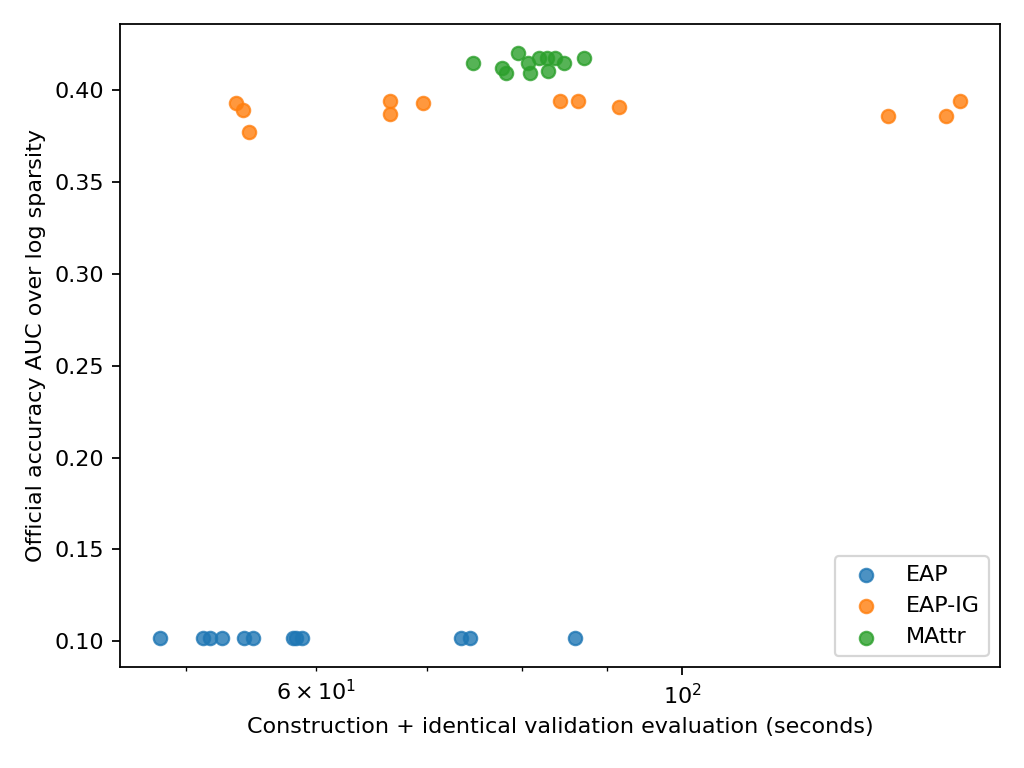

circuit_size_curves.png


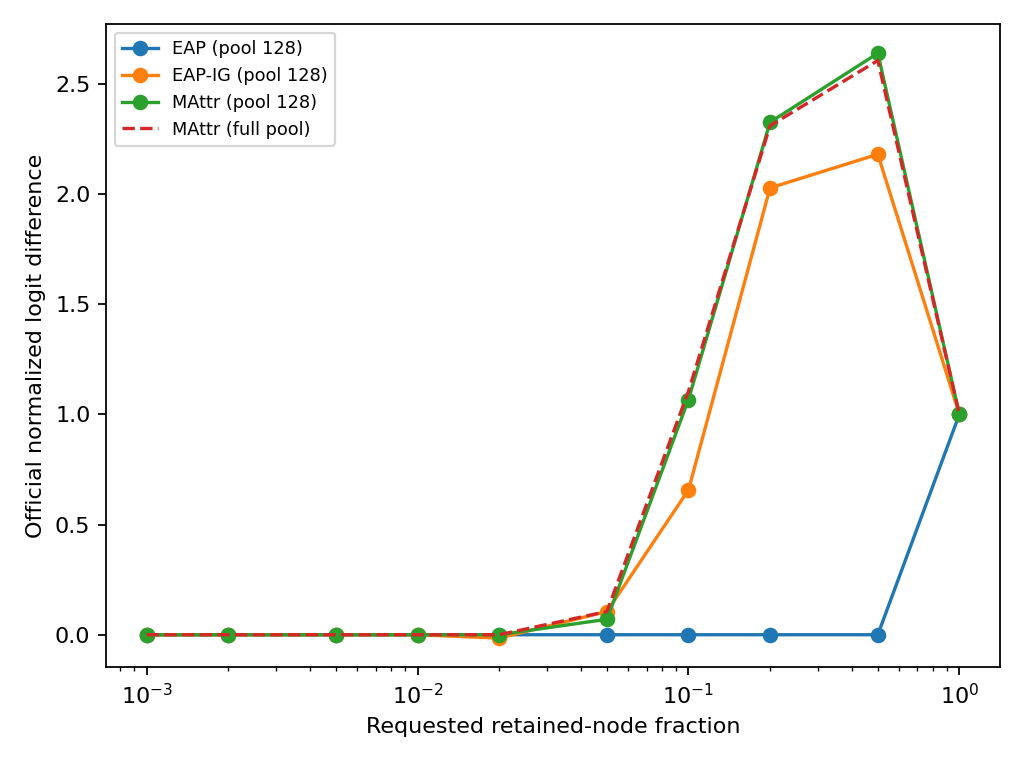

generalization_gap.png


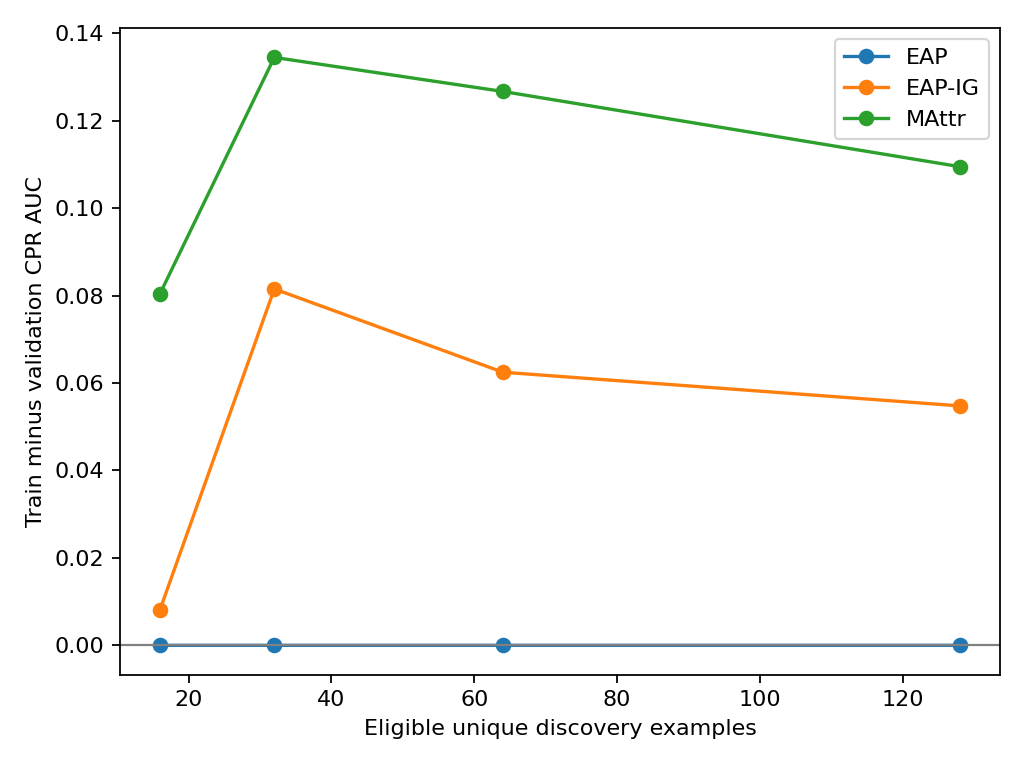

public_test_confirmation.png


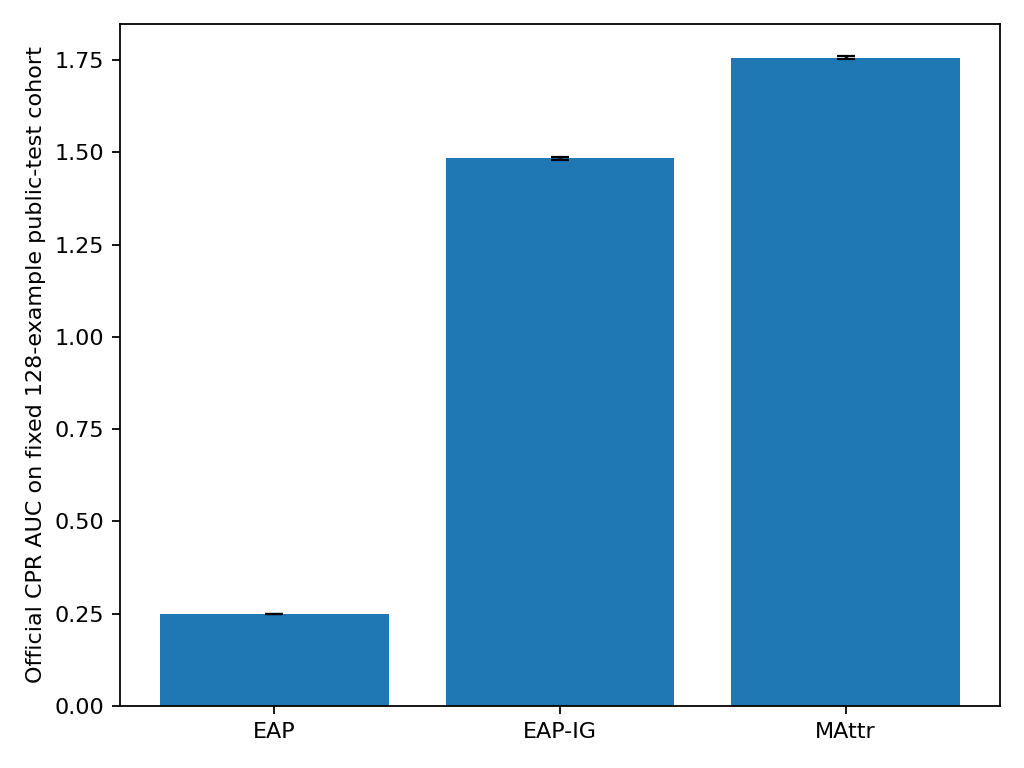

quality_vs_compute.png


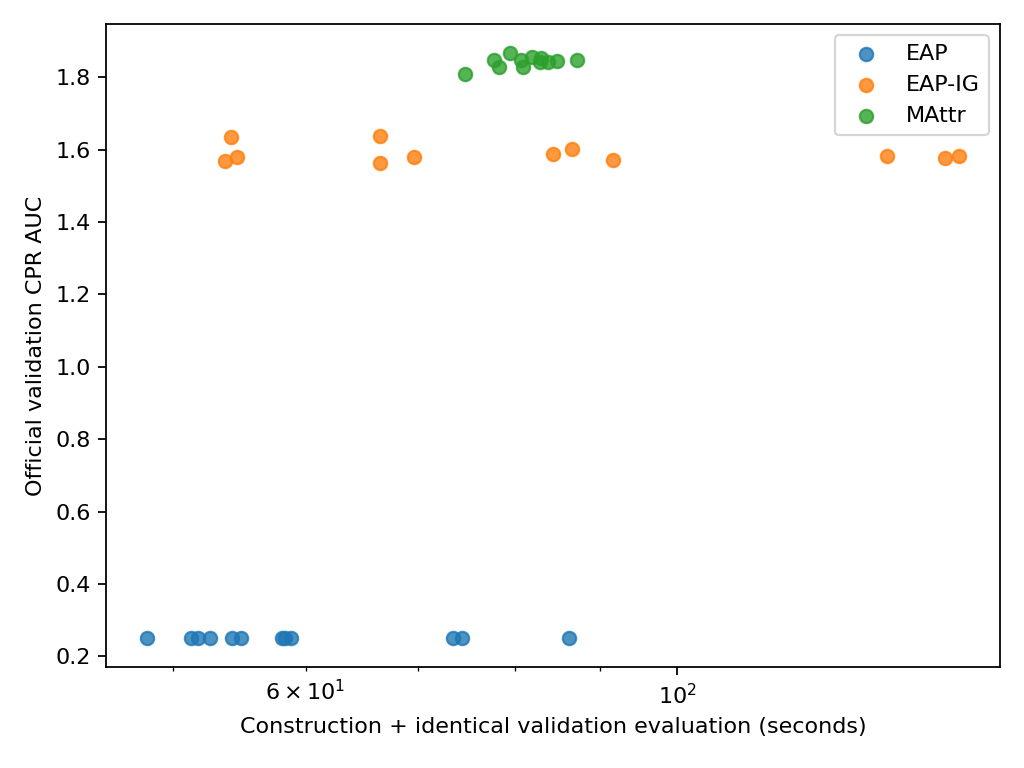

quality_vs_construction_compute.png


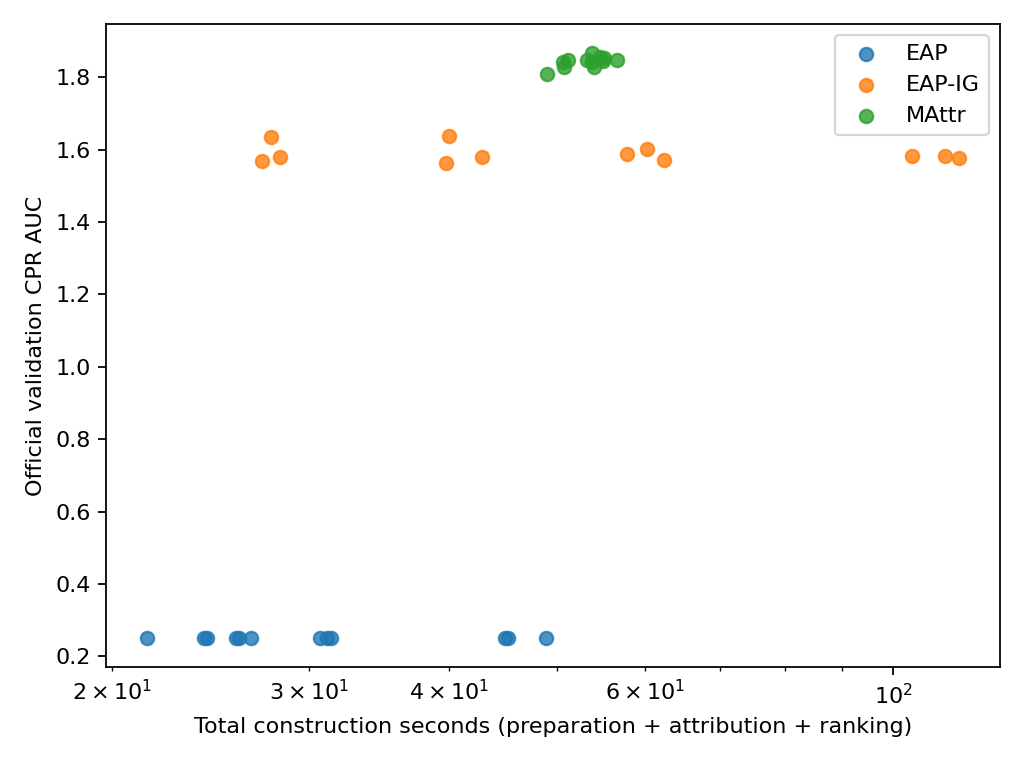

quality_vs_discovery_data.png


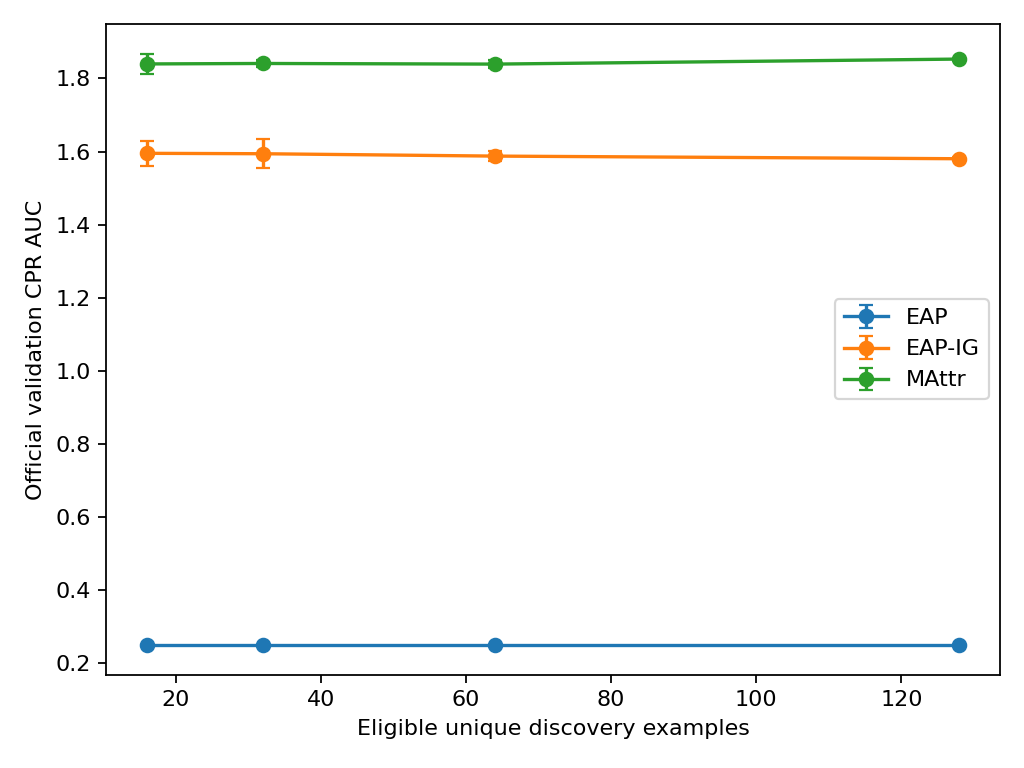

quality_vs_steps.png


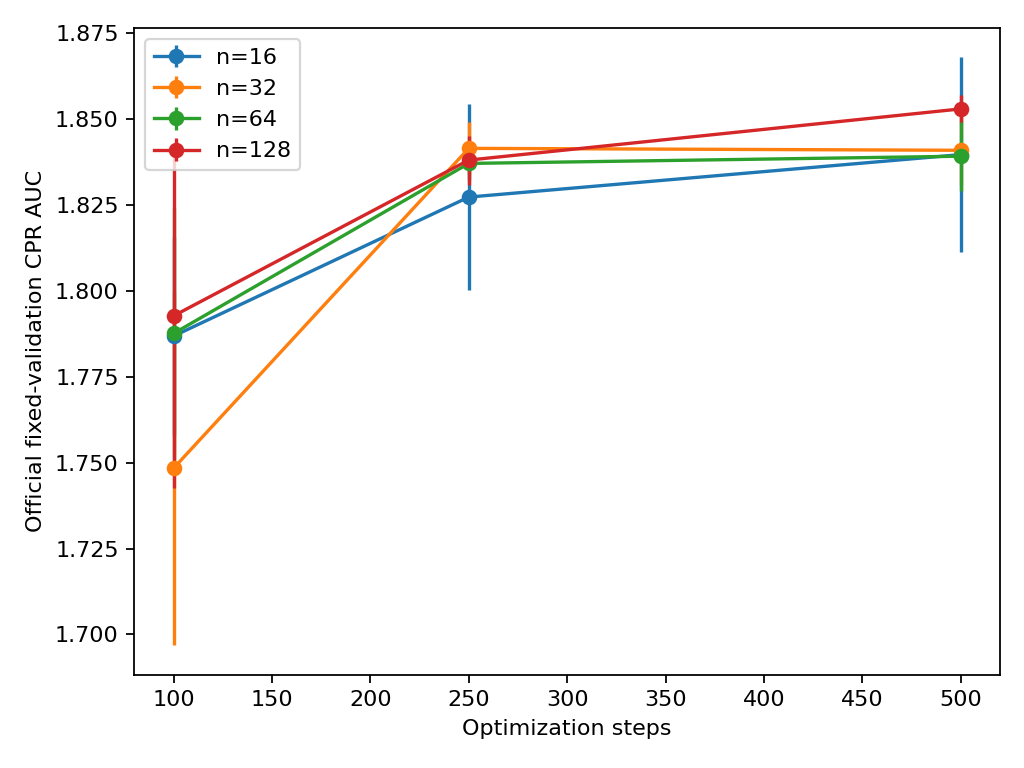

quality_vs_training_runtime.png


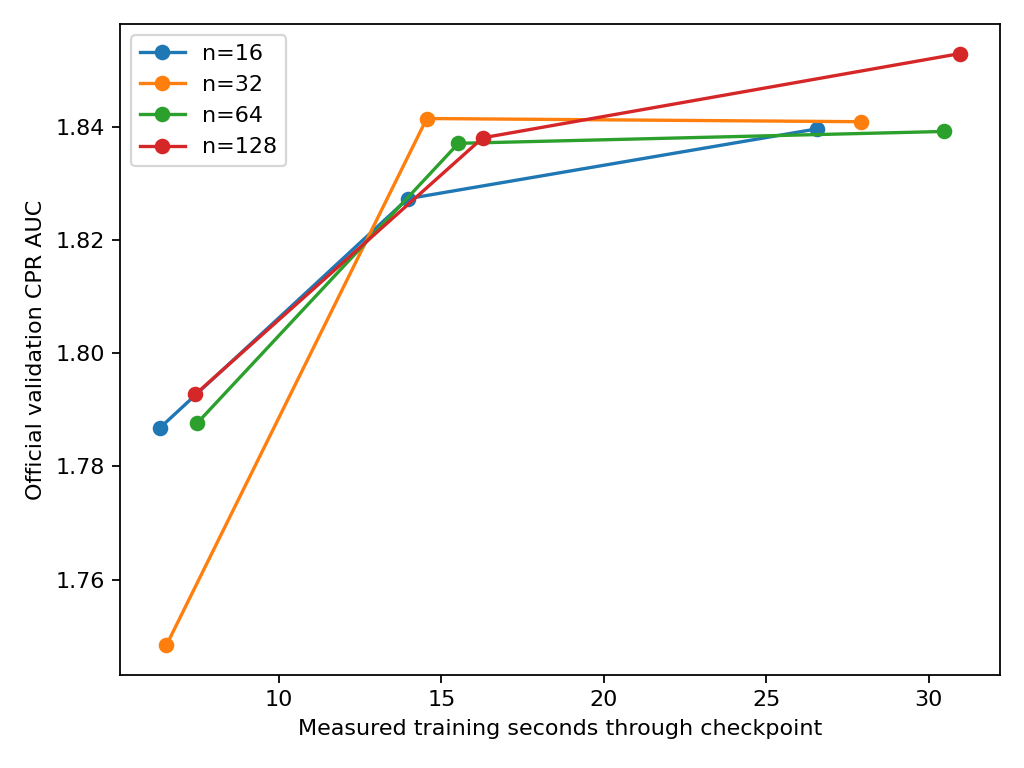

train_vs_validation.png


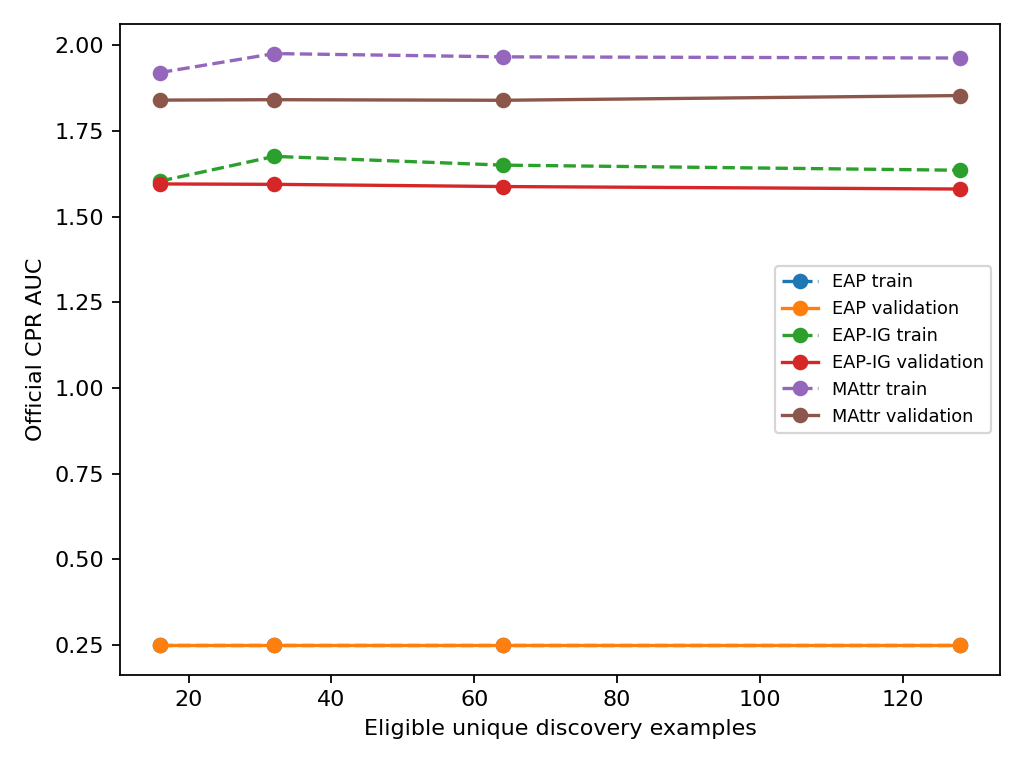

training_loss.png


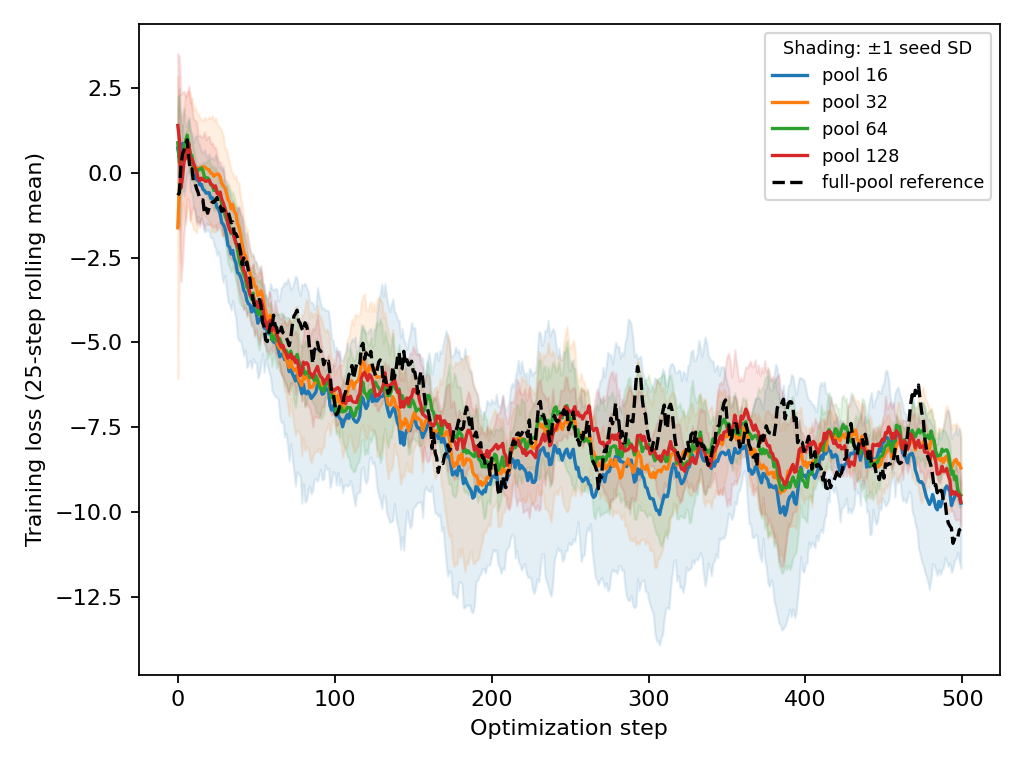

# MAttr reproduction on GPT-2 Small / MIB IOI

Campaign: `results/mattr_reproduction/20261015T223201Z`. Branch: `codex/mattr-reproduction`. Public test is used only for the frozen final confirmation; discovery and selection use train/validation.

## Reproduction and provenance

Attribution calls the unmodified official MAttr trainer and CLI; evaluation calls the pinned official MIB evaluator. The local adapter selects rows, records compute, and saves/restores scores, Adam state and RNGs. Official tests (6) and adapter tests (5) passed; fresh and resumed updates matched the upstream training loop bit for bit in deterministic tensor tests. The CUDA smoke trained and evaluated GPT-2 before the reference.

Pinned MAttr: `af82b2eef145dd3e66c793a413352d6931a152d7`. Exact MIB/EAP commits, package versions, lock/source hashes, commands, prompt manifests and counters are in each run directory. WSL Ubuntu / RTX 3060 12 GB uses an isolated Python 3.12 environment and the official locked lm/dev de

In [4]:
from IPython.display import display, Image
for path in sorted(RESULTS.glob('*.png')):
    print(path.name)
    display(Image(filename=str(path)))
report=ROOT/'MATTR_REPRODUCTION_REPORT.md'
if report.exists(): print(report.read_text(encoding='utf-8'))
else: print('No research conclusions have been generated yet.')
